In [26]:
# import required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
# load diabetes dataset
df = pd.read_csv(r"/Users/pratikvilasgadhe/Desktop/Programming/AI_ML/practical/diabetes.csv")
print("Dataset Loads Sucessfully!")
df.info()
# df.describe()
df.head()

Dataset Loads Sucessfully!
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    int64  
 2   SkinThickness             768 non-null    int64  
 3   Insulin                   768 non-null    int64  
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 48.1 KB


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,50,35,0,33.6,0.627,50,1
1,85,66,29,0,26.6,0.351,31,0
2,183,64,0,0,23.3,0.672,52,1
3,150,66,23,94,28.1,0.167,21,0
4,150,40,35,168,43.1,2.288,33,1


In [29]:
# drop the output label data from dataset and put it into x_input
x_input=df.drop('Outcome',axis=1)
x_input

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,148,50,35,0,33.6,0.627,50
1,85,66,29,0,26.6,0.351,31
2,183,64,0,0,23.3,0.672,52
3,150,66,23,94,28.1,0.167,21
4,150,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...
763,101,76,48,180,32.9,0.171,63
764,122,70,27,0,36.8,0.340,27
765,121,72,23,112,26.2,0.245,30
766,126,60,0,0,30.1,0.349,47


In [ ]:
# add the output label data into y_output
y_output = df['Outcome']
y_output.head()

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [ ]:
# split the data into training and testing
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x_input,y_output,test_size = 0.2 , random_state = 42)
print("training data split into 80% : ",x_train.shape)
print("testing data split into 20% : ",x_test.shape)


training data split into 80% :  (614, 7)
testing data split into 20% :  (154, 7)


(154,)

In [34]:
# use of knn algorithm
from sklearn.neighbors import KNeighborsClassifier
knn_default = KNeighborsClassifier()
knn_default

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None


In [ ]:
# fit the training input (80%) and training output (80%) data
knn_default.fit(x_train,y_train)

# predict the output based on 20% testing data
y_pred=knn_default.predict(x_test)

array([0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0])

In [38]:
# finding accuracy score
from sklearn.metrics import accuracy_score

print("accuracy score (dff in test-output and predicted output) : ",accuracy_score(y_test,y_pred))

accuracy score (dff in test-output and predicted output) :  0.6818181818181818


In [46]:
# now with cross validation
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
score = cross_val_score(knn_default,x_input,y_output,cv=5,scoring='accuracy')
print(score)
accuracy_score(y_test,y_pred)
score.mean()

[0.7012987  0.72077922 0.70779221 0.75163399 0.68627451]


np.float64(0.7135557253204311)

In [54]:
accuracy = []
for i in range(1,21):
    knn1= KNeighborsClassifier(n_neighbors = i)
    knn1.fit(x_train,y_train)
    y_predict = knn1.predict(x_test)
    accuracy_score_1 = accuracy_score(y_test,y_predict)
    accuracy.append(accuracy_score_1)

print(accuracy)

max_accuracy = max(accuracy)
print(max_accuracy)

score = cross_val_score(knn1,x_input,y_output,cv=10,scoring='accuracy')
score
mean= score.mean()

[0.6558441558441559, 0.6883116883116883, 0.6363636363636364, 0.6948051948051948, 0.6818181818181818, 0.7272727272727273, 0.7142857142857143, 0.7337662337662337, 0.7077922077922078, 0.7662337662337663, 0.7272727272727273, 0.7727272727272727, 0.7597402597402597, 0.7727272727272727, 0.7597402597402597, 0.7532467532467533, 0.7467532467532467, 0.7467532467532467, 0.7402597402597403, 0.7142857142857143]
0.7727272727272727


In [57]:
score = cross_val_score(knn1,x_input,y_output,cv=10,scoring='accuracy')
print(score)
mean= score.mean()
print(mean)

[0.75324675 0.72727273 0.71428571 0.68831169 0.71428571 0.76623377
 0.75324675 0.81818182 0.76315789 0.76315789]
0.746138072453862


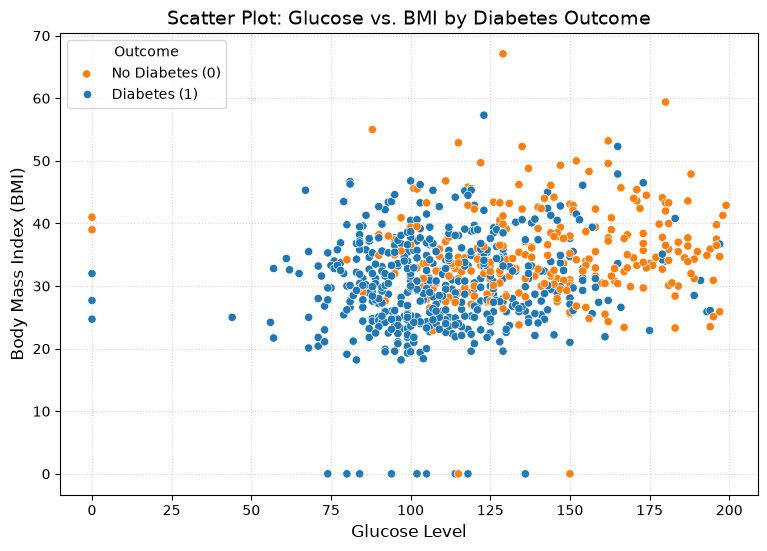

In [63]:
# --- Scatter Plot 2: Feature Relationships (Glucose vs BMI) ---
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Glucose",
    y="BMI",
    hue="Outcome"
)

plt.title("Scatter Plot: Glucose vs. BMI by Diabetes Outcome", fontsize=14)
plt.xlabel("Glucose Level", fontsize=12)
plt.ylabel("Body Mass Index (BMI)", fontsize=12)
plt.legend(title="Outcome", labels=["No Diabetes (0)", "Diabetes (1)"])
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()